# S18 · Calidad del aire en México con Excel: de datos crudos a decisiones

| | |
|---|---|
| **Programa** | IA Explorer – TCS / TecNM (CPFIA) |
| **Módulo** | 02 |
| **Sesión** | 18 · Excel para análisis de datos I |
| **Fecha** | 2026-11-10 |
| **Autor** | Luis Saúl González Guerra |

## 1. Objetivo

Aplicar el proceso de la Sesión 18 (*De datos crudos a decisiones de negocio*) a un problema real de contaminación: **la calidad del aire en las ciudades de México**, usando la base pública mundial de la Organización Mundial de la Salud (OMS).

El notebook procesa los datos y genera tres entregables:

1. `outputs/S18_Calidad_Aire_Mexico.xlsx`: libro de Excel con los 8 estadios del proceso (datos crudos, datos limpios en Tabla, fórmulas base, tabla dinámica, gráficas, dashboard interactivo y decisión).
2. `outputs/S18_Dashboard_Calidad_Aire_Mexico.pdf`: dashboard en PDF que redacta todo el proceso y el resultado.
3. Gráficas PNG en `outputs/` para el README.

### El Excel Mindset aplicado

| Pregunta | Métrica | Dimensión | Filtro | Análisis accionable |
|---|---|---|---|---|
| ¿Qué entidades de México respiran el aire más contaminado y cómo ha cambiado en el tiempo? | Promedio anual de PM2.5 en µg/m³ (`AVERAGE`) | Entidad federativa (filas) y año (columnas) | Contaminante y año | Priorizar las entidades donde invertir primero en control de emisiones y monitoreo |

## 2. Configuración

Imports, rutas relativas y constantes del análisis en una sola celda. Los valores guía son las **Guías de Calidad del Aire de la OMS 2021** (promedio anual).

In [1]:
import io
import textwrap
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from openpyxl import Workbook
from openpyxl.chart import BarChart, LineChart, Reference
from openpyxl.formatting.rule import ColorScaleRule
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from openpyxl.workbook.defined_name import DefinedName
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.worksheet.table import Table, TableStyleInfo

BASE_DIR = Path.cwd().parent
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
OUTPUT_DIR = BASE_DIR / "outputs"
for d in (RAW_DIR, PROCESSED_DIR, OUTPUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

WHO_URL = (
    "https://cdn.who.int/media/docs/default-source/air-pollution-documents/"
    "air-quality-and-health/who-ambient-air-quality-database-version-2026-v8.xlsx"
    "?sfvrsn=95d122a4_5&download=true"
)
RAW_FILE = RAW_DIR / "who_ambient_air_quality_database_v8_2026.xlsx"
XLSX_OUT = OUTPUT_DIR / "S18_Calidad_Aire_Mexico.xlsx"
PDF_OUT = OUTPUT_DIR / "S18_Dashboard_Calidad_Aire_Mexico.pdf"

GUIA_OMS = {"PM2.5": 5, "PM10": 15, "NO2": 10}
COBERTURA_MINIMA = 75
PERIODO_RECIENTE = (2018, 2022)

AZUL, NARANJA, GRIS, TINTA = "#2F5D8A", "#E8704A", "#9AA5B1", "#1F2A36"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})

## 3. Carga de datos (Estadio 1: Datos crudos)

**Fuente:** [WHO Ambient Air Quality Database, versión 8.0 (junio 2026)](https://www.who.int/publications/m/item/who-ambient-air-quality-database-(update-jun-2026)). Reúne promedios anuales de PM10, PM2.5 y NO2 medidos en estaciones terrestres de más de 7,000 asentamientos en el mundo. Para México, el origen de las mediciones es el **SINAICA del INECC**.

**Descripción:** cada fila es una ciudad o municipio en un año, con la concentración promedio anual de cada contaminante en µg/m³, el porcentaje de cobertura temporal de la medición, el número y tipo de estaciones y la población.

El archivo se descarga solo si no existe en `data/raw/`. El Excel original **no viene estructurado**: toda la fila es un texto CSV metido en la columna A, y las filas con textos largos se partieron en varias celdas. Es exactamente el problema de *Datos crudos* de la clase.

In [2]:
if not RAW_FILE.exists():
    req = urllib.request.Request(WHO_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as resp:
        RAW_FILE.write_bytes(resp.read())

crudo = pd.read_excel(RAW_FILE, header=None, dtype=str)
print(f"Forma del Excel original: {crudo.shape[0]:,} filas x {crudo.shape[1]} columnas")
print("Celdas con datos por columna:", crudo.notna().sum().to_dict())
crudo.head(3)

Forma del Excel original: 55,221 filas x 13 columnas
Celdas con datos por columna: {0: 55218, 1: 9473, 2: 2758, 3: 907, 4: 337, 5: 154, 6: 39, 7: 21, 8: 16, 9: 12, 10: 4, 11: 1, 12: 1}


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,"who_region,""iso3"",""country_name"",""city"",""year""...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"EMR,""AFG"",""Afghanistan"",""Kabul/AFG"",2019,""V5.0...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"EUR,""ALB"",""Albania"",""Durres/ALB"",2014,""V8.0 (2...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Reconstrucción equivalente a **Datos → Texto en columnas** de Excel: se unen los pedazos de cada fila y se interpreta el texto como CSV. Los valores `NA` se convierten en vacíos reales.

In [3]:
lineas = crudo.apply(lambda fila: "".join(v for v in fila if isinstance(v, str)), axis=1)
mundo = pd.read_csv(io.StringIO("\n".join(lineas)), na_values=["NA"])
print(f"Base mundial: {mundo.shape[0]:,} registros, {mundo['country_name'].nunique()} países")
mundo.head()

Base mundial: 55,214 registros, 126 países


,who_region,iso3,country_name,city,year,version,pm10_concentration,pm25_concentration,no2_concentration,pm10_tempcov,...,no2_tempcov,type_of_stations,number_stations,reference,web_link,population,population_source,latitude,longitude,who_ms
0,EMR,AFG,Afghanistan,Kabul/AFG,2019.0,V5.0 (2022) (n=1),NaN,119.77,NaN,NaN,...,NaN,NA (n=1),1,"U.S. Department of State, United States Enviro...","[[[""EPA AirNow DOS"",""http://airnow.gov/index.c...",4221532.0,Imputed_from_UNWUP2018 (n=1),34.5358,69.1905,1
1,EUR,ALB,Albania,Durres/ALB,2014.0,V8.0 (2026) (n=1),13.85,7.74,36.74,40.0,...,9.0,Traffic-Urban (n=1),1,European Environmental Agency (n=1),https://discomap.eea.europa.eu/App/AQViewer/in...,NaN,NA (n=1),41.3199,19.4492,1
2,EUR,ALB,Albania,Durres/ALB,2015.0,V8.0 (2026) (n=1),17.65,12.60,26.63,79.0,...,84.0,Traffic-Urban (n=1),1,European Environmental Agency (n=1),https://discomap.eea.europa.eu/App/AQViewer/in...,NaN,NA (n=1),41.3199,19.4492,1
3,EUR,ALB,Albania,Durres/ALB,2016.0,V8.0 (2026) (n=1),24.53,14.30,24.78,84.0,...,88.0,Traffic-Urban (n=1),1,European Environmental Agency (n=1),https://discomap.eea.europa.eu/App/AQViewer/in...,NaN,NA (n=1),41.3199,19.4492,1
4,EUR,ALB,Albania,Durres/ALB,2017.0,V8.0 (2026) (n=1),25.56,14.71,23.22,52.0,...,50.0,Traffic-Urban (n=1),1,European Environmental Agency (n=1),https://discomap.eea.europa.eu/App/AQViewer/in...,NaN,NA (n=1),41.3199,19.4492,1


## 4. Exploración de datos (EDA)

Se revisa la base mundial y el subconjunto de México: tamaño, años, vacíos y calidad de la medición.

In [4]:
mex_crudo = mundo[mundo["iso3"] == "MEX"].copy()
lineas_mex = pd.concat([lineas.iloc[[0]], lineas[lineas.str.contains(',"MEX",', regex=False)]])

print(f"Registros de México: {len(mex_crudo)}")
print(f"Municipios: {mex_crudo['city'].nunique()} | Años: {int(mex_crudo['year'].min())}-{int(mex_crudo['year'].max())}")
print("\nRegistros con medición por contaminante:")
print(mex_crudo[["pm25_concentration", "pm10_concentration", "no2_concentration"]].notna().sum())
mex_crudo[["pm25_concentration", "pm10_concentration", "no2_concentration",
           "pm25_tempcov", "pm10_tempcov", "no2_tempcov"]].describe().round(1)

Registros de México: 868
Municipios: 114 | Años: 2010-2023

Registros con medición por contaminante:
pm25_concentration    435
pm10_concentration    680
no2_concentration     591
dtype: int64


,pm25_concentration,pm10_concentration,no2_concentration,pm25_tempcov,pm10_tempcov,no2_tempcov
count,435.0,680.0,591.0,435.0,680.0,587.0
mean,21.9,51.1,62.7,88.0,90.2,85.7
std,7.7,16.4,82.3,8.2,8.2,19.2
min,4.8,20.7,3.8,17.0,16.0,13.0
25%,17.4,39.5,26.6,83.0,86.0,85.0
50%,21.0,48.7,39.5,89.0,92.0,92.0
75%,25.0,61.3,52.7,94.0,96.0,96.0
max,75.8,137.4,365.0,100.0,100.0,100.0


In [5]:
mex_crudo["city"].sample(8, random_state=1).tolist()

['Pachuca de Soto Hidalgo/MEX',
 'Pachuca de Soto Hidalgo/MEX',
 'Toluca Mexico/MEX',
 'Metepec Mexico/MEX',
 'Juarez Chihuahua/MEX',
 'Pachuca de Soto Hidalgo/MEX',
 'Nogales Sonora/MEX',
 'Garcia Nuevo Leon/MEX']

Hallazgos de la exploración que guían la limpieza:

- La columna `city` mezcla municipio, estado y país en un solo texto (`"Coyoacan Ciudad de Mexico/MEX"`).
- Hay nombres inconsistentes para el mismo municipio (`Cadereyta Jimenez` y `Cadereyta de Jimenez`; `Tlaquepaque` y `San Pedro Tlaquepaque`) y uno sin estado (`Soledad de Graciano Sanchez/MEX`).
- `type_of_stations` trae conteos pegados al texto (`"Urban (n=2)"`).
- Algunas mediciones cubren muy poco del año (cobertura temporal mínima de 13%), lo que distorsiona el promedio anual.
- Columnas como `reference`, `web_link` o `version` son de presentación o trazabilidad y no aportan al análisis.

## 5. Limpieza y transformación (Estadio 2: Datos limpios)

Se aplican las **Reglas de Higiene** de la clase. Cada regla se registra en una bitácora que después va al Excel y al PDF, junto con su equivalente en Excel.

In [6]:
ESTADOS = {
    "Aguascalientes": "Aguascalientes", "Baja California": "Baja California", "Chihuahua": "Chihuahua",
    "Ciudad de Mexico": "Ciudad de México", "Coahuila": "Coahuila", "Durango": "Durango",
    "Guanajuato": "Guanajuato", "Hidalgo": "Hidalgo", "Jalisco": "Jalisco", "Mexico": "Estado de México",
    "Michoacan": "Michoacán", "Morelos": "Morelos", "Nayarit": "Nayarit", "Nuevo Leon": "Nuevo León",
    "Oaxaca": "Oaxaca", "Puebla": "Puebla", "Queretaro": "Querétaro", "San Luis Potosi": "San Luis Potosí",
    "Sonora": "Sonora", "Tabasco": "Tabasco", "Tlaxcala": "Tlaxcala", "Veracruz": "Veracruz",
    "Yucatan": "Yucatán", "Zacatecas": "Zacatecas",
}
REGIONES = {
    "Norte": ["Baja California", "Sonora", "Chihuahua", "Coahuila", "Nuevo León", "Durango"],
    "Occidente-Bajío": ["Jalisco", "Nayarit", "Guanajuato", "Querétaro", "Aguascalientes",
                        "Zacatecas", "San Luis Potosí", "Michoacán"],
    "Centro": ["Ciudad de México", "Estado de México", "Hidalgo", "Morelos", "Puebla", "Tlaxcala"],
    "Sur-Sureste": ["Veracruz", "Tabasco", "Oaxaca", "Yucatán"],
}
REGION_DE = {estado: region for region, estados in REGIONES.items() for estado in estados}
CORRECCIONES_MUNICIPIO = {
    "Cadereyta Jimenez Nuevo Leon": "Cadereyta de Jimenez Nuevo Leon",
    "San Pedro Tlaquepaque Jalisco": "Tlaquepaque Jalisco",
    "Soledad de Graciano Sanchez": "Soledad de Graciano Sanchez San Luis Potosi",
}

bitacora = []

def registrar(regla, problema, filas, accion, excel):
    bitacora.append({"Regla": regla, "Problema detectado": problema, "Filas afectadas": int(filas),
                     "Acción": accion, "Equivalente en Excel": excel})

registrar("Estructura", "Cada fila es un texto CSV en la columna A, partido en varias celdas",
          len(crudo), "Unir los pedazos y separar por comas",
          "CONCAT de columnas + Datos > Texto en columnas")
registrar("Sin vacíos", "Valores escritos como texto 'NA'",
          int((lineas.str.count(",NA") > 0).sum()), "Convertir 'NA' en celda vacía",
          "Buscar y reemplazar 'NA' por vacío")
registrar("Separación estricta", "La base es mundial y solo interesa México",
          len(mundo) - len(mex_crudo), "Filtrar iso3 = MEX", "Filtro automático por país")

mex = mex_crudo.copy()
lugar = mex["city"].str.replace("/MEX", "", regex=False).str.strip()
afectadas = lugar.isin(CORRECCIONES_MUNICIPIO).sum()
lugar = lugar.replace(CORRECCIONES_MUNICIPIO)
registrar("Estandarización", "Mismo municipio con dos nombres y un municipio sin estado", afectadas,
          "Unificar nombre y completar el estado", "Buscar y reemplazar / BUSCARV a un catálogo")

def separar_lugar(texto):
    for clave in sorted(ESTADOS, key=len, reverse=True):
        if texto.endswith(" " + clave):
            return texto[: -len(clave) - 1].strip(), ESTADOS[clave]
    return texto, None

mex[["Municipio", "Estado"]] = lugar.apply(lambda t: pd.Series(separar_lugar(t)))
assert mex["Estado"].notna().all(), mex.loc[mex["Estado"].isna(), "city"].unique()
registrar("Separación estricta", "Municipio, estado y país juntos en la columna city", len(mex),
          "Separar en Municipio y Estado y poner acentos al estado", "Texto en columnas / IZQUIERDA, EXTRAE")

mex["Region"] = mex["Estado"].map(REGION_DE)
tipo_sin_dato = mex["type_of_stations"].str.startswith("NA", na=True)
registrar("Separación estricta", "Tipo de estación viene como 'NA (n=1)': sin información para México",
          int(tipo_sin_dato.sum()), "No se lleva la columna a la tabla de análisis", "Eliminar columna")

for pref, nombre in (("pm25", "PM2.5"), ("pm10", "PM10"), ("no2", "NO2")):
    baja = mex[f"{pref}_tempcov"] < COBERTURA_MINIMA
    registrar("Datos confiables", f"{nombre}: medición con cobertura del año menor a {COBERTURA_MINIMA}%",
              int((baja & mex[f"{pref}_concentration"].notna()).sum()),
              "Dejar la medición vacía para no distorsionar promedios", "SI(cobertura<75, \"\", valor)")
    mex.loc[baja, f"{pref}_concentration"] = np.nan

limpio = (mex.rename(columns={"year": "Anio", "pm25_concentration": "PM25", "pm10_concentration": "PM10",
                              "no2_concentration": "NO2", "number_stations": "Estaciones",
                              "population": "Poblacion", "latitude": "Latitud", "longitude": "Longitud"})
          [["Anio", "Estado", "Municipio", "Region", "PM25", "PM10", "NO2", "Estaciones",
            "Poblacion", "Latitud", "Longitud"]])
limpio["Anio"] = limpio["Anio"].astype(int)
limpio["Estaciones"] = limpio["Estaciones"].astype("Int64")
limpio["Poblacion"] = limpio["Poblacion"].round().astype("Int64")
limpio[["PM25", "PM10", "NO2"]] = limpio[["PM25", "PM10", "NO2"]].round(2)

duplicados = limpio.duplicated(["Anio", "Estado", "Municipio"]).sum()
registrar("Sin duplicados", "Mismo municipio y año repetido tras unificar nombres", duplicados,
          "Conservar un registro por municipio y año", "Datos > Quitar duplicados")
limpio = limpio.drop_duplicates(["Anio", "Estado", "Municipio"])

sin_medicion = limpio[["PM25", "PM10", "NO2"]].isna().all(axis=1)
registrar("Sin vacíos", "Registros sin ningún contaminante válido", sin_medicion.sum(),
          "Eliminar la fila completa", "Filtro por vacíos + eliminar filas")
limpio = limpio[~sin_medicion]
registrar("Separación estricta", "Columnas de presentación o trazabilidad (reference, web_link, version)",
          len(limpio), "No se llevan a la tabla de análisis", "Ocultar o eliminar columnas")

limpio = limpio.sort_values(["Anio", "Estado", "Municipio"]).reset_index(drop=True)
limpio.to_csv(PROCESSED_DIR / "calidad_aire_mexico_limpio.csv", index=False)
bitacora_df = pd.DataFrame(bitacora)
bitacora_df.to_csv(PROCESSED_DIR / "bitacora_limpieza.csv", index=False)

print(f"Tabla limpia: {limpio.shape[0]} filas x {limpio.shape[1]} columnas")
print(f"{limpio['Municipio'].nunique()} municipios en {limpio['Estado'].nunique()} entidades")
bitacora_df

Tabla limpia: 857 filas x 11 columnas
111 municipios en 24 entidades


,Regla,Problema detectado,Filas afectadas,Acción,Equivalente en Excel
0,Estructura,"Cada fila es un texto CSV en la columna A, par...",55221,Unir los pedazos y separar por comas,CONCAT de columnas + Datos > Texto en columnas
1,Sin vacíos,Valores escritos como texto 'NA',48666,Convertir 'NA' en celda vacía,Buscar y reemplazar 'NA' por vacío
2,Separación estricta,La base es mundial y solo interesa México,54346,Filtrar iso3 = MEX,Filtro automático por país
3,Estandarización,Mismo municipio con dos nombres y un municipio...,6,Unificar nombre y completar el estado,Buscar y reemplazar / BUSCARV a un catálogo
4,Separación estricta,"Municipio, estado y país juntos en la columna ...",868,Separar en Municipio y Estado y poner acentos ...,"Texto en columnas / IZQUIERDA, EXTRAE"
5,Separación estricta,Tipo de estación viene como 'NA (n=1)': sin in...,868,No se lleva la columna a la tabla de análisis,Eliminar columna
6,Datos confiables,PM2.5: medición con cobertura del año menor a 75%,6,Dejar la medición vacía para no distorsionar p...,"SI(cobertura<75, """", valor)"
7,Datos confiables,PM10: medición con cobertura del año menor a 75%,12,Dejar la medición vacía para no distorsionar p...,"SI(cobertura<75, """", valor)"
8,Datos confiables,NO2: medición con cobertura del año menor a 75%,41,Dejar la medición vacía para no distorsionar p...,"SI(cobertura<75, """", valor)"
9,Sin duplicados,Mismo municipio y año repetido tras unificar n...,0,Conservar un registro por municipio y año,Datos > Quitar duplicados


In [7]:
limpio.head()

,Anio,Estado,Municipio,Region,PM25,PM10,NO2,Estaciones,Poblacion,Latitud,Longitud
0,2010,Baja California,Mexicali,Norte,NaN,NaN,39.5,1,933123,32.63110,-115.44510
1,2010,Baja California,Tijuana,Norte,NaN,NaN,35.7,1,1579083,32.49750,-116.97690
2,2010,Chihuahua,Chihuahua,Norte,NaN,NaN,33.9,1,833160,28.71610,-106.13330
3,2010,Chihuahua,Juarez,Norte,NaN,65.72,NaN,5,1625,31.71574,-106.46564
4,2010,Ciudad de México,Alvaro Obregon,Centro,NaN,35.50,47.0,1,743088,19.32510,-99.20410


## 6. Análisis (Estadios 3 a 5: Tabla, fórmulas y tabla dinámica)

Primero se replica en pandas lo que hará Excel, para tener los números de referencia del dashboard y del PDF.

**Estadio 4. Columnas calculadas:** `Veces_Guia_PM25` (cuántas veces supera la guía OMS) y `Categoria_PM25` con una función `SI` anidada sobre los objetivos intermedios de la OMS 2021.

In [8]:
def categoria_pm25(valor):
    if pd.isna(valor):
        return "Sin dato"
    if valor > 35:
        return "Muy alto (>35)"
    if valor > 25:
        return "Alto (25-35)"
    if valor > 15:
        return "Moderado (15-25)"
    if valor > 10:
        return "Bajo (10-15)"
    if valor > 5:
        return "Cerca de guía (5-10)"
    return "Cumple guía (≤5)"

limpio["Veces_Guia_PM25"] = (limpio["PM25"] / GUIA_OMS["PM2.5"]).round(2)
limpio["Categoria_PM25"] = limpio["PM25"].apply(categoria_pm25)
limpio["Categoria_PM25"].value_counts()

Categoria_PM25
Sin dato                428
Moderado (15-25)        255
Alto (25-35)             91
Bajo (10-15)             68
Muy alto (>35)           12
Cumple guía (≤5)          2
Cerca de guía (5-10)      1
Name: count, dtype: int64

**Estadio 5. Tabla dinámica:** PM2.5 promedio con *Estado* en filas y *Año* en columnas.

In [9]:
pivote_pm25 = limpio.pivot_table(index="Estado", columns="Anio", values="PM25", aggfunc="mean").round(1)
pivote_pm25["Promedio"] = limpio.groupby("Estado")["PM25"].mean().round(1)
pivote_pm25 = pivote_pm25.dropna(subset=["Promedio"]).sort_values("Promedio", ascending=False)
pivote_pm25

Anio,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,Promedio
Estado,,,,,,,,,,,,,,,
Estado de México,22.8,29.0,28.4,29.7,26.5,28.0,27.4,31.7,27.9,25.8,24.8,27.7,24.6,20.1,26.9
Jalisco,NaN,NaN,NaN,NaN,19.7,NaN,27.2,26.0,24.7,NaN,24.7,NaN,29.9,NaN,25.5
Baja California,NaN,NaN,NaN,NaN,23.9,22.2,NaN,21.7,23.0,24.9,21.0,32.0,28.8,NaN,24.9
Aguascalientes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.6,NaN,NaN,NaN,NaN,NaN,24.6
Hidalgo,NaN,NaN,NaN,61.8,50.4,33.0,21.4,19.8,20.4,17.1,16.8,17.1,18.9,NaN,23.8
Ciudad de México,22.5,25.9,23.8,25.0,22.7,24.5,22.7,21.8,22.8,21.9,19.2,19.1,20.2,20.8,22.5
Nuevo León,23.8,26.0,21.8,NaN,28.7,26.1,NaN,NaN,23.4,22.2,20.1,21.5,20.7,19.9,21.7
Chihuahua,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.9,16.6,NaN,14.1,13.6,39.9,NaN,20.0
Puebla,NaN,NaN,NaN,NaN,29.9,19.8,17.6,17.8,18.3,20.3,NaN,14.6,15.1,NaN,19.2


In [10]:
ini, fin = PERIODO_RECIENTE
reciente = limpio[limpio["Anio"].between(ini, fin)]

resumen_estado = (reciente.groupby("Estado")
                  .agg(PM25=("PM25", "mean"), PM10=("PM10", "mean"), NO2=("NO2", "mean"),
                       Municipios=("Municipio", "nunique"))
                  .round(1).sort_values("PM25", ascending=False))
tendencia = limpio.groupby("Anio")[["PM25", "PM10", "NO2"]].mean().round(1)
conteo_tendencia = limpio.groupby("Anio")["PM25"].count()

kpi = {
    "pm25_nacional": reciente["PM25"].mean(),
    "pm10_nacional": reciente["PM10"].mean(),
    "no2_nacional": reciente["NO2"].mean(),
    "pct_sobre_guia_pm25": (reciente["PM25"].dropna() > GUIA_OMS["PM2.5"]).mean() * 100,
    "pct_sobre_oi4": (reciente["PM25"].dropna() > 10).mean() * 100,
    "municipios": limpio["Municipio"].nunique(),
    "estados": limpio["Estado"].nunique(),
    "estados_pm25": limpio.dropna(subset=["PM25"])["Estado"].nunique(),
}
kpi["veces_guia"] = kpi["pm25_nacional"] / GUIA_OMS["PM2.5"]
top3 = resumen_estado["PM25"].dropna().head(3)
peor_muni = (reciente.groupby(["Municipio", "Estado"])["PM25"].mean().dropna()
             .sort_values(ascending=False).head(5).round(1))
{k: round(v, 1) for k, v in kpi.items()}

{'pm25_nacional': np.float64(19.6),
 'pm10_nacional': np.float64(47.3),
 'no2_nacional': np.float64(37.6),
 'pct_sobre_guia_pm25': np.float64(99.2),
 'pct_sobre_oi4': np.float64(98.7),
 'municipios': 111,
 'estados': 24,
 'estados_pm25': 22,
 'veces_guia': np.float64(3.9)}

In [11]:
peor_muni

Municipio           Estado          
San Mateo Atenco    Estado de México    35.5
Guadalajara         Jalisco             29.9
Metepec             Estado de México    29.5
Toluca              Estado de México    29.0
Atotonilco de Tula  Hidalgo             28.4
Name: PM25, dtype: float64

**Contexto mundial.** Promedio de PM2.5 de las ciudades con medición en cada región de la OMS, en el mismo periodo. Las regiones no tienen la misma cantidad de ciudades monitoreadas, así que la comparación es orientativa.

In [12]:
REGIONES_OMS = {"AFR": "África", "AMR": "Américas", "EMR": "Mediterráneo Oriental", "EUR": "Europa",
                "SEAR": "Asia Sudoriental", "WPR": "Pacífico Occidental"}
mundo_rec = mundo[mundo["year"].between(ini, fin)]
comparacion = (mundo_rec.groupby("who_region")["pm25_concentration"].mean()
               .rename(index=REGIONES_OMS).to_frame("PM25"))
comparacion.loc["México"] = kpi["pm25_nacional"]
comparacion.loc["Mundo"] = mundo_rec["pm25_concentration"].mean()
comparacion = comparacion.round(1).sort_values("PM25", ascending=False)
paises = mundo_rec.groupby("country_name")["pm25_concentration"].mean().dropna()
rank_mexico = int(paises.rank(ascending=False)["Mexico"])
print(f"México ocupa el lugar {rank_mexico} de {len(paises)} países con dato de PM2.5 ({ini}-{fin}).")
comparacion

México ocupa el lugar 45 de 101 países con dato de PM2.5 (2018-2022).


,PM25
who_region,
Mediterráneo Oriental,49.1
Asia Sudoriental,38.9
Pacífico Occidental,33.5
África,27.7
México,19.6
Mundo,19.0
Europa,12.8
Américas,10.7


## 7. Resultados (Estadios 3 a 8 en Excel)

### 7.1 Libro de Excel

El libro se arma con `openpyxl` y queda **vivo**: las columnas calculadas, la tabla dinámica, los KPIs y las gráficas son fórmulas de Excel que se recalculan al abrir el archivo y al cambiar los filtros.

| Hoja | Estadio de la clase |
|---|---|
| `00_Proceso` | Mapa del proceso y Excel Mindset |
| `01_Datos_Crudos` | 1. Datos crudos, tal como llegan |
| `02_Bitacora_Limpieza` | 2. Reglas de higiene aplicadas |
| `03_Datos_Limpios` | 3. Tabla de Excel `tblCalidadAire` con columnas calculadas |
| `04_Formulas_Base` | 4. SUM, AVERAGE, COUNT, COUNTA, IF como utilidad |
| `05_Tabla_Dinamica` | 5. Estado x Año con filtro de contaminante |
| `06_Dashboard` | 6 y 7. Gráficas y dashboard con filtros |
| `07_Contexto_Mundial` | Comparación de México contra las regiones de la OMS |
| `08_Decision` | 8. Insight y decisión |

`openpyxl` no puede crear tablas dinámicas nativas ni segmentadores. Por eso la hoja `05_Tabla_Dinamica` replica la tabla dinámica con `PROMEDIO.SI.CONJUNTO` y listas desplegables que funcionan como segmentadores. La misma hoja trae los pasos para insertar la tabla dinámica nativa sobre `tblCalidadAire`.

In [13]:
HEADER_FILL = PatternFill("solid", fgColor="2F5D8A")
SUB_FILL = PatternFill("solid", fgColor="DCE6F0")
KPI_FILL = PatternFill("solid", fgColor="F4F6F8")
ACCENT_FILL = PatternFill("solid", fgColor="FBE3DA")
WHITE_BOLD = Font(bold=True, color="FFFFFF")
TITLE = Font(bold=True, size=16, color="1F2A36")
SUBTITLE = Font(italic=True, size=10, color="5A6773")
THIN = Border(*(Side(style="thin", color="C9D3DD"),) * 4)
WRAP = Alignment(wrap_text=True, vertical="top")
CENTER = Alignment(horizontal="center", vertical="center", wrap_text=True)
CONTAMINANTES = ["PM2.5", "PM10", "NO2"]

def titulo(ws, texto, subtitulo=None):
    ws["A1"] = texto
    ws["A1"].font = TITLE
    if subtitulo:
        ws["A2"] = subtitulo
        ws["A2"].font = SUBTITLE
    ws.sheet_view.showGridLines = False

def encabezado(ws, fila, col, valores, fill=HEADER_FILL, font=WHITE_BOLD):
    for i, v in enumerate(valores):
        c = ws.cell(row=fila, column=col + i, value=v)
        c.fill, c.font, c.alignment, c.border = fill, font, CENTER, THIN

def anchos(ws, valores):
    for col, ancho in valores.items():
        ws.column_dimensions[col].width = ancho

def tabla_simple(ws, fila, col, df, formatos=None):
    encabezado(ws, fila, col, list(df.columns))
    for r, registro in enumerate(df.itertuples(index=False), start=fila + 1):
        for c, valor in enumerate(registro, start=col):
            celda = ws.cell(row=r, column=c, value=None if pd.isna(valor) else valor)
            celda.border, celda.alignment = THIN, WRAP
            if formatos and df.columns[c - col] in formatos:
                celda.number_format = formatos[df.columns[c - col]]

def lista(ws, celda, opciones):
    dv = DataValidation(type="list", formula1='"' + ",".join(opciones) + '"', allow_blank=False)
    ws.add_data_validation(dv)
    dv.add(ws[celda])
    ws[celda].fill = ACCENT_FILL
    ws[celda].font = Font(bold=True, size=12)
    ws[celda].alignment = CENTER
    ws[celda].border = THIN

wb = Workbook()

**Hojas 00 a 02:** proceso, datos crudos y bitácora de limpieza.

In [14]:
ws = wb.active
ws.title = "00_Proceso"
titulo(ws, "Calidad del aire en México: de datos crudos a decisiones",
       "Práctica S18 · Excel para análisis de datos I · Fuente: OMS, Ambient Air Quality Database v8.0 (2026)")
encabezado(ws, 4, 1, ["Pregunta", "Métrica", "Dimensión", "Filtro", "Análisis accionable"])
mindset = ["¿Qué entidades de México respiran el aire más contaminado y cómo ha cambiado?",
           "Promedio anual de PM2.5 (µg/m³) · AVERAGE", "Entidad (filas) y año (columnas)",
           "Contaminante y año", "Priorizar dónde invertir primero en control de emisiones y monitoreo"]
for i, v in enumerate(mindset, start=1):
    c = ws.cell(row=5, column=i, value=v)
    c.alignment, c.border = WRAP, THIN
ws.row_dimensions[5].height = 48
encabezado(ws, 7, 1, ["Estadio", "Qué se hizo", "Hoja"])
estadios = [
    ("1. Datos crudos", "Descarga del Excel mundial de la OMS. Cada fila es texto CSV en la columna A.", "01_Datos_Crudos"),
    ("2. Datos limpios", "Reglas de higiene: sin vacíos, separación estricta, estandarización, datos confiables.", "02_Bitacora_Limpieza"),
    ("3. Tabla de Excel", "Rango convertido en Tabla (Ctrl+T) llamada tblCalidadAire.", "03_Datos_Limpios"),
    ("4. Fórmulas y cálculos", "SUM, AVERAGE, COUNT, COUNTA e IF; columnas Veces_Guia_PM25 y Categoria_PM25.", "04_Formulas_Base"),
    ("5. Tabla dinámica", "Estado x Año con filtro de contaminante.", "05_Tabla_Dinamica"),
    ("6. Gráficos", "Barras para comparar entidades y líneas para la tendencia.", "06_Dashboard"),
    ("7. Dashboard", "KPIs y gráficas que responden a los filtros de contaminante y año.", "06_Dashboard"),
    ("8. Reporte de negocio", "Insight y decisión basada en los datos.", "08_Decision"),
]
for r, fila in enumerate(estadios, start=8):
    for c, v in enumerate(fila, start=1):
        celda = ws.cell(row=r, column=c, value=v)
        celda.alignment, celda.border = WRAP, THIN
anchos(ws, {"A": 26, "B": 60, "C": 30, "D": 22, "E": 40})

ws = wb.create_sheet("01_Datos_Crudos")
titulo(ws, "Estadio 1 · Datos crudos (México)",
       "Así llega cada fila en el Excel original de la OMS: un solo texto CSV en la columna A.")
ws["A4"] = "Fila del archivo original"
ws["A4"].fill, ws["A4"].font = HEADER_FILL, WHITE_BOLD
for r, texto in enumerate(lineas_mex, start=5):
    ws.cell(row=r, column=1, value=texto)
ws.column_dimensions["A"].width = 180
ws.freeze_panes = "A5"

ws = wb.create_sheet("02_Bitacora_Limpieza")
titulo(ws, "Estadio 2 · Bitácora de limpieza", "Reglas de higiene aplicadas a los datos crudos")
tabla_simple(ws, 4, 1, bitacora_df, {"Filas afectadas": "#,##0"})
anchos(ws, {"A": 20, "B": 55, "C": 14, "D": 45, "E": 42})

**Hoja 03:** Tabla de Excel `tblCalidadAire` con dos columnas calculadas por fórmula y nombres definidos para usar en las demás hojas.

In [15]:
ws = wb.create_sheet("03_Datos_Limpios")
columnas = list(limpio.columns[:11]) + ["Veces_Guia_PM25", "Categoria_PM25"]
ws.append(columnas)
for i, registro in enumerate(limpio[columnas[:11]].itertuples(index=False), start=2):
    ws.append([None if pd.isna(v) else (v.item() if hasattr(v, "item") else v) for v in registro]
              + [f'=IF(ISNUMBER(E{i}),ROUND(E{i}/{GUIA_OMS["PM2.5"]},2),"")',
                 f'=IF(NOT(ISNUMBER(E{i})),"Sin dato",IF(E{i}>35,"Muy alto (>35)",IF(E{i}>25,"Alto (25-35)",'
                 f'IF(E{i}>15,"Moderado (15-25)",IF(E{i}>10,"Bajo (10-15)",IF(E{i}>5,"Cerca de guía (5-10)",'
                 f'"Cumple guía (≤5)"))))))'])
ULTIMA = len(limpio) + 1
tabla = Table(displayName="tblCalidadAire", ref=f"A1:{get_column_letter(len(columnas))}{ULTIMA}")
tabla.tableStyleInfo = TableStyleInfo(name="TableStyleMedium2", showRowStripes=True)
ws.add_table(tabla)
ws.freeze_panes = "A2"
for col in "EFGL":
    for celda in ws[col][1:]:
        celda.number_format = "0.00"
for celda in ws["I"][1:]:
    celda.number_format = "#,##0"
anchos(ws, {"A": 8, "B": 18, "C": 28, "D": 16, "E": 9, "F": 9, "G": 9, "H": 11, "I": 12,
            "J": 10, "K": 10, "L": 16, "M": 22})

RANGOS = {"d_Anio": "A", "d_Estado": "B", "d_Municipio": "C", "d_Region": "D", "d_PM25": "E", "d_PM10": "F",
          "d_NO2": "G", "d_Estaciones": "H", "d_Poblacion": "I", "d_Categoria": "M"}
for nombre, col in RANGOS.items():
    wb.defined_names[nombre] = DefinedName(nombre, attr_text=f"'03_Datos_Limpios'!${col}$2:${col}${ULTIMA}")

def rango_contaminante(celda):
    return f'CHOOSE(MATCH({celda},{{"PM2.5","PM10","NO2"}},0),d_PM25,d_PM10,d_NO2)'

def guia_contaminante(celda):
    return f'CHOOSE(MATCH({celda},{{"PM2.5","PM10","NO2"}},0),5,15,10)'

**Hoja 04:** las cinco fórmulas base de la clase, cada una respondiendo una pregunta sobre los datos.

In [16]:
ws = wb.create_sheet("04_Formulas_Base")
titulo(ws, "Estadio 4 · Fórmulas base como utilidad", "Cada fórmula responde una pregunta concreta sobre los datos")
encabezado(ws, 4, 1, ["Fórmula", "Pregunta", "Fórmula en Excel", "Resultado", "Lectura"])
formulas = [
    ("SUM", "¿Cuántas estaciones de monitoreo suman todos los registros?",
     "=SUM(d_Estaciones)", "#,##0", "Total de estaciones-año en la base."),
    ("AVERAGE", "¿Cuál es el PM2.5 promedio de todas las mediciones?",
     "=AVERAGE(d_PM25)", "0.0", f"La guía OMS es {GUIA_OMS['PM2.5']} µg/m³."),
    ("COUNT", "¿Cuántos registros tienen una medición válida de PM2.5?",
     "=COUNT(d_PM25)", "#,##0", "COUNT solo cuenta celdas con números."),
    ("COUNTA", "¿Cuántos registros municipio-año hay en total?",
     "=COUNTA(d_Municipio)", "#,##0", "COUNTA cuenta celdas no vacías."),
    ("IF", "¿El promedio de PM2.5 cumple la guía de la OMS?",
     f'=IF(AVERAGE(d_PM25)<={GUIA_OMS["PM2.5"]},"Cumple","No cumple")', "@",
     "La columna Categoria_PM25 usa IF anidados con los objetivos intermedios OMS."),
    ("COUNTIF", "¿Cuántas mediciones de PM2.5 cumplen la guía?",
     f'=COUNTIF(d_PM25,"<={GUIA_OMS["PM2.5"]}")', "#,##0", "Variante condicional de COUNT."),
    ("AVERAGEIFS", f"¿PM2.5 promedio de la región Centro en {fin}?",
     f'=AVERAGEIFS(d_PM25,d_Region,"Centro",d_Anio,{fin})', "0.0", "Es la fórmula que alimenta la tabla dinámica."),
]
for r, (nombre, pregunta, formula, formato, lectura) in enumerate(formulas, start=5):
    valores = [nombre, pregunta, formula, formula, lectura]
    for c, v in enumerate(valores, start=1):
        celda = ws.cell(row=r, column=c, value=v)
        celda.alignment, celda.border = WRAP, THIN
    ws.cell(row=r, column=3).data_type = "s"
    ws.cell(row=r, column=3).font = Font(name="Consolas", size=10)
    ws.cell(row=r, column=1).font = Font(bold=True)
    ws.cell(row=r, column=4).number_format = formato
    ws.cell(row=r, column=4).font = Font(bold=True, size=12, color="2F5D8A")
anchos(ws, {"A": 13, "B": 48, "C": 44, "D": 14, "E": 50})

**Hoja 05:** tabla dinámica Estado x Año. La celda del filtro cambia el contaminante y toda la matriz se recalcula, con escala de color para resaltar los valores altos.

In [17]:
ws = wb.create_sheet("05_Tabla_Dinamica")
titulo(ws, "Estadio 5 · Tabla dinámica: promedio anual por entidad y año",
       "Métrica = promedio (Valores) · Dimensión = Estado (Filas) y Año (Columnas) · Filtro = Contaminante")
ws["A3"] = "Filtro · Contaminante:"
ws["A3"].font = Font(bold=True)
ws["B3"] = "PM2.5"
lista(ws, "B3", CONTAMINANTES)
ws["D3"] = "Guía OMS (µg/m³):"
ws["D3"].font = Font(bold=True)
ws["F3"] = "=" + guia_contaminante("$B$3")
ws["F3"].font = Font(bold=True, color="E8704A")

anios = sorted(limpio["Anio"].unique())
estados = sorted(limpio["Estado"].unique())
FILA_ENC = 5
encabezado(ws, FILA_ENC, 1, ["Estado"] + [int(a) for a in anios] + ["Promedio"])
for r, estado in enumerate(estados, start=FILA_ENC + 1):
    ws.cell(row=r, column=1, value=estado).border = THIN
    for c, _ in enumerate(anios, start=2):
        col = get_column_letter(c)
        ws.cell(row=r, column=c,
                value=f'=IFERROR(AVERAGEIFS({rango_contaminante("$B$3")},d_Estado,$A{r},d_Anio,{col}${FILA_ENC}),"")')
    ws.cell(row=r, column=len(anios) + 2,
            value=f'=IFERROR(AVERAGEIFS({rango_contaminante("$B$3")},d_Estado,$A{r}),"")').font = Font(bold=True)
FILA_TOTAL = FILA_ENC + len(estados) + 1
ws.cell(row=FILA_TOTAL, column=1, value="Total México").font = Font(bold=True)
for c in range(2, len(anios) + 2):
    col = get_column_letter(c)
    ws.cell(row=FILA_TOTAL, column=c,
            value=f'=IFERROR(AVERAGEIFS({rango_contaminante("$B$3")},d_Anio,{col}${FILA_ENC}),"")')
ws.cell(row=FILA_TOTAL, column=len(anios) + 2, value=f'=AVERAGE({rango_contaminante("$B$3")})')
ultima_col = get_column_letter(len(anios) + 2)
for fila in ws[f"A{FILA_ENC + 1}:{ultima_col}{FILA_TOTAL}"]:
    for celda in fila:
        celda.border = THIN
        if celda.column > 1:
            celda.number_format = "0.0"
            celda.alignment = CENTER
for celda in ws[FILA_TOTAL]:
    celda.fill = SUB_FILL
    celda.font = Font(bold=True)
ws.conditional_formatting.add(
    f"B{FILA_ENC + 1}:{ultima_col}{FILA_TOTAL - 1}",
    ColorScaleRule(start_type="min", start_color="F4F8FB", mid_type="percentile", mid_value=50,
                   mid_color="F6C7B4", end_type="max", end_color="E8704A"))
anchos(ws, {"A": 20, **{get_column_letter(c): 8 for c in range(2, len(anios) + 3)}})
ws.freeze_panes = f"B{FILA_ENC + 1}"

pasos = [
    "Cómo crear la tabla dinámica nativa en Excel con los mismos datos:",
    "1. Ve a 03_Datos_Limpios, selecciona una celda de la Tabla tblCalidadAire.",
    "2. Insertar > Tabla dinámica > Nueva hoja de cálculo.",
    "3. Arrastra Estado a Filas, Anio a Columnas y PM25 a Valores.",
    "4. En Valores cambia 'Suma' por 'Promedio' (Configuración de campo de valor).",
    "5. Agrega Region a Filtros e inserta un Segmentador de datos de Region para filtrar con un clic.",
    "6. Inserta un Gráfico dinámico de columnas desde la tabla dinámica.",
]
for i, texto in enumerate(pasos, start=FILA_TOTAL + 2):
    ws.cell(row=i, column=1, value=texto).font = Font(bold=(i == FILA_TOTAL + 2))

**Hoja 06:** dashboard con dos filtros (contaminante y año), cinco KPIs y dos gráficas. Las tablas auxiliares a la derecha alimentan las gráficas. Siguiendo la *Regla de Oro* de la clase, cada gráfica nace de una tabla.

In [18]:
ws = wb.create_sheet("06_Dashboard")
titulo(ws, "Estadios 6 y 7 · Dashboard de calidad del aire en México",
       "Cambia los filtros naranjas: los KPIs y las gráficas se recalculan solos")
ws["A4"], ws["A5"] = "Contaminante:", "Año:"
ws["A4"].font = ws["A5"].font = Font(bold=True)
ws["B4"], ws["B5"] = "PM2.5", "Todos"
lista(ws, "B4", CONTAMINANTES)
lista(ws, "B5", ["Todos"] + [str(int(a)) for a in anios])

SEL = rango_contaminante("$B$4")
CRIT_ANIO = 'IF($B$5="Todos",">0",VALUE($B$5))'
kpis = [
    ("Promedio nacional (µg/m³)", f"=IFERROR(AVERAGEIFS({SEL},d_Anio,{CRIT_ANIO}),\"\")", "0.0"),
    ("Guía OMS (µg/m³)", "=" + guia_contaminante("$B$4"), "0"),
    ("Veces sobre la guía", '=IFERROR(A8/C8,"")', '0.0"x"'),
    ("% de mediciones sobre la guía", f'=IFERROR(COUNTIFS({SEL},">"&C8,d_Anio,{CRIT_ANIO})/COUNTIFS({SEL},">=0",d_Anio,{CRIT_ANIO}),"")', "0%"),
    ("Mediciones (municipio-año)", f'=COUNTIFS({SEL},">=0",d_Anio,{CRIT_ANIO})', "#,##0"),
]
for i, (etiqueta, formula, formato) in enumerate(kpis):
    col = 2 + i * 2 - 1
    etiqueta_celda = ws.cell(row=7, column=col, value=etiqueta)
    valor = ws.cell(row=8, column=col, value=formula)
    ws.merge_cells(start_row=7, start_column=col, end_row=7, end_column=col + 1)
    ws.merge_cells(start_row=8, start_column=col, end_row=8, end_column=col + 1)
    etiqueta_celda.font = Font(size=9, color="5A6773", bold=True)
    etiqueta_celda.alignment = CENTER
    valor.font = Font(size=22, bold=True, color="E8704A" if i == 2 else "1F2A36")
    valor.alignment = CENTER
    valor.number_format = formato
    for r in (7, 8):
        for c in (col, col + 1):
            ws.cell(row=r, column=c).fill = KPI_FILL
ws.row_dimensions[8].height = 38
ws["A10"] = "Entidad más alta con el filtro actual:"
ws["A10"].font = Font(bold=True)
ws["D10"] = "=IFERROR(INDEX(N5:N{0},MATCH(_xlfn.AGGREGATE(4,6,O5:O{0}),O5:O{0},0)),\"\")".format(4 + len(estados))
ws["D10"].font = Font(bold=True, size=12, color="E8704A")

encabezado(ws, 4, 14, ["Estado", "Promedio"], fill=SUB_FILL, font=Font(bold=True))
for r, estado in enumerate(estados, start=5):
    ws.cell(row=r, column=14, value=estado)
    ws.cell(row=r, column=15,
            value=f"=IFERROR(AVERAGEIFS({SEL},d_Estado,N{r},d_Anio,{CRIT_ANIO}),NA())").number_format = "0.0"
fila_t = 6 + len(estados)
encabezado(ws, fila_t, 14, ["Año", "Promedio", "Guía OMS"], fill=SUB_FILL, font=Font(bold=True))
for r, anio in enumerate(anios, start=fila_t + 1):
    ws.cell(row=r, column=14, value=int(anio))
    ws.cell(row=r, column=15, value=f"=IFERROR(AVERAGEIFS({SEL},d_Anio,N{r}),NA())").number_format = "0.0"
    ws.cell(row=r, column=16, value="=$C$8")
anchos(ws, {**{get_column_letter(c): 12 for c in range(1, 11)}, "N": 20, "O": 11, "P": 10})

barras = BarChart()
barras.type = "bar"
barras.title = "Promedio por entidad (filtro actual)"
barras.y_axis.title = "µg/m³"
barras.add_data(Reference(ws, min_col=15, min_row=4, max_row=4 + len(estados)), titles_from_data=True)
barras.set_categories(Reference(ws, min_col=14, min_row=5, max_row=4 + len(estados)))
barras.legend = None
barras.height, barras.width = 13, 16
barras.series[0].graphicalProperties.solidFill = "2F5D8A"
ws.add_chart(barras, "A12")

lineas_graf = LineChart()
lineas_graf.title = "Tendencia nacional vs guía OMS"
lineas_graf.y_axis.title = "µg/m³"
lineas_graf.add_data(Reference(ws, min_col=15, max_col=16, min_row=fila_t, max_row=fila_t + len(anios)),
                     titles_from_data=True)
lineas_graf.set_categories(Reference(ws, min_col=14, min_row=fila_t + 1, max_row=fila_t + len(anios)))
lineas_graf.height, lineas_graf.width = 13, 14
lineas_graf.series[0].graphicalProperties.line.solidFill = "2F5D8A"
lineas_graf.series[1].graphicalProperties.line.solidFill = "E8704A"
lineas_graf.series[1].graphicalProperties.line.dashStyle = "dash"
ws.add_chart(lineas_graf, "G12")

**Hojas 07 y 08:** contexto mundial y decisión.

In [19]:
ws = wb.create_sheet("07_Contexto_Mundial")
titulo(ws, f"México frente al mundo · PM2.5 promedio {ini}-{fin}",
       "Promedio de las ciudades con medición en cada región de la OMS (comparación orientativa)")
contexto = comparacion.reset_index().rename(columns={"index": "Región", "who_region": "Región", "PM25": "PM2.5 (µg/m³)"})
tabla_simple(ws, 4, 1, contexto, {"PM2.5 (µg/m³)": "0.0"})
graf = BarChart()
graf.title = "PM2.5 promedio por región de la OMS"
graf.add_data(Reference(ws, min_col=2, min_row=4, max_row=4 + len(contexto)), titles_from_data=True)
graf.set_categories(Reference(ws, min_col=1, min_row=5, max_row=4 + len(contexto)))
graf.legend = None
graf.series[0].graphicalProperties.solidFill = "2F5D8A"
ws.add_chart(graf, "D4")
ws.cell(row=6 + len(contexto), column=1,
        value=f"México ocupa el lugar {rank_mexico} de {len(paises)} países con dato de PM2.5 en {ini}-{fin}.")
anchos(ws, {"A": 26, "B": 16})

top_txt = ", ".join(f"{e} ({v:.1f})" for e, v in top3.items())
insight = (f"Entre {ini} y {fin}, el PM2.5 promedio de las ciudades monitoreadas de México fue de "
           f"{kpi['pm25_nacional']:.1f} µg/m³, {kpi['veces_guia']:.1f} veces la guía de la OMS. "
           f"El {kpi['pct_sobre_guia_pm25']:.1f}% de las mediciones municipales supera la guía. "
           f"Las entidades con mayor PM2.5 son {top_txt} µg/m³. "
           f"Además, solo {kpi['estados_pm25']} de las {kpi['estados']} entidades con estaciones reportan PM2.5.")
decision = (f"Asignar la mayor parte del presupuesto de control de emisiones a {top3.index[0]}, "
            f"{top3.index[1]} y {top3.index[2]}, empezando por sus municipios con mayor PM2.5. "
            "En paralelo, financiar monitores de PM2.5 en las entidades que hoy solo miden PM10 o NO2, "
            "porque sin dato no se puede priorizar.")
ws = wb.create_sheet("08_Decision")
titulo(ws, "Estadio 8 · La decisión", "Del dashboard al storytelling")
for r, (etiqueta, texto, fill) in enumerate([("El insight (la verdad de los datos)", insight, SUB_FILL),
                                             ("La decisión (la acción)", decision, ACCENT_FILL)], start=4):
    fila = (r - 4) * 3 + 4
    ws.cell(row=fila, column=1, value=etiqueta).font = Font(bold=True, size=12)
    celda = ws.cell(row=fila + 1, column=1, value=texto)
    ws.merge_cells(start_row=fila + 1, start_column=1, end_row=fila + 1, end_column=8)
    celda.alignment, celda.fill = WRAP, fill
    ws.row_dimensions[fila + 1].height = 80
ws.cell(row=11, column=1, value="Municipios con mayor PM2.5 promedio en el periodo").font = Font(bold=True)
tabla_simple(ws, 12, 1, peor_muni.reset_index().rename(columns={"PM25": "PM2.5 (µg/m³)"}), {"PM2.5 (µg/m³)": "0.0"})
anchos(ws, {"A": 28, "B": 20, "C": 14})

wb.calculation.fullCalcOnLoad = True
wb.active = wb.sheetnames.index("06_Dashboard")
wb.save(XLSX_OUT)
print(f"Libro guardado: {XLSX_OUT.relative_to(BASE_DIR)} con hojas {wb.sheetnames}")

Libro guardado: outputs/S18_Calidad_Aire_Mexico.xlsx con hojas ['00_Proceso', '01_Datos_Crudos', '02_Bitacora_Limpieza', '03_Datos_Limpios', '04_Formulas_Base', '05_Tabla_Dinamica', '06_Dashboard', '07_Contexto_Mundial', '08_Decision']


### 7.2 Gráficas

Las mismas vistas del dashboard de Excel, exportadas como PNG para el README y el PDF.

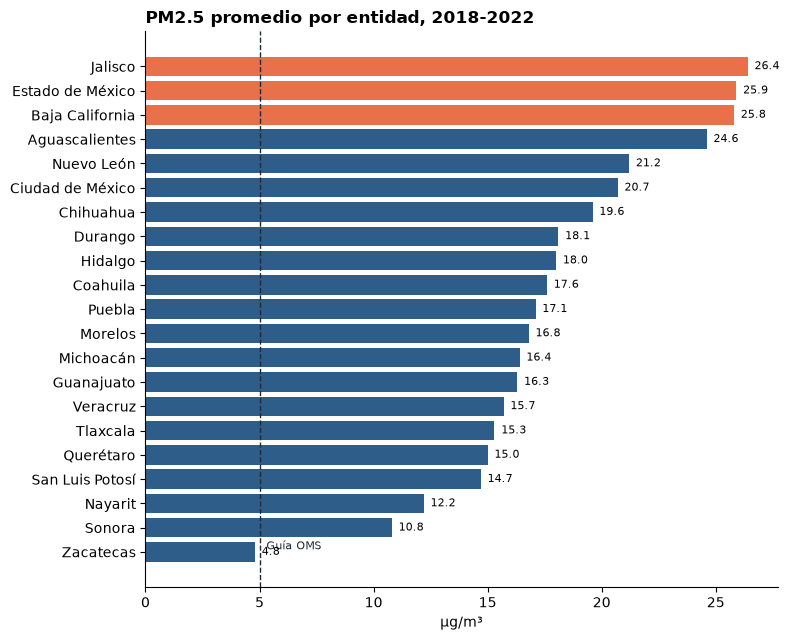

In [20]:
fig_estados, ax = plt.subplots(figsize=(8, 6.5))
datos = resumen_estado["PM25"].dropna().sort_values()
colores = [NARANJA if e in top3.index else AZUL for e in datos.index]
ax.barh(datos.index, datos.values, color=colores)
ax.axvline(GUIA_OMS["PM2.5"], color=TINTA, ls="--", lw=1)
ax.text(GUIA_OMS["PM2.5"] + 0.3, 0, "Guía OMS", fontsize=8, color=TINTA, va="bottom")
for y, v in enumerate(datos.values):
    ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=8)
ax.set_title(f"PM2.5 promedio por entidad, {ini}-{fin}", loc="left", fontweight="bold")
ax.set_xlabel("µg/m³")
fig_estados.tight_layout()
fig_estados.savefig(OUTPUT_DIR / "pm25_por_entidad.png", dpi=150, bbox_inches="tight")
plt.show()

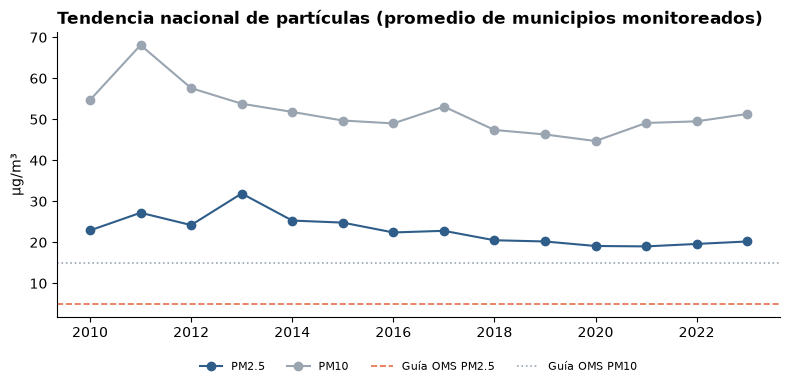

In [21]:
fig_tend, ax = plt.subplots(figsize=(8, 4))
for col, color, etiqueta in (("PM25", AZUL, "PM2.5"), ("PM10", GRIS, "PM10")):
    ax.plot(tendencia.index, tendencia[col], marker="o", color=color, label=etiqueta)
ax.axhline(GUIA_OMS["PM2.5"], color=NARANJA, ls="--", lw=1.2, label="Guía OMS PM2.5")
ax.axhline(GUIA_OMS["PM10"], color=GRIS, ls=":", lw=1.2, label="Guía OMS PM10")
ax.set_title("Tendencia nacional de partículas (promedio de municipios monitoreados)", loc="left", fontweight="bold")
ax.set_ylabel("µg/m³")
ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig_tend.tight_layout()
fig_tend.savefig(OUTPUT_DIR / "tendencia_particulas.png", dpi=150, bbox_inches="tight")
plt.show()

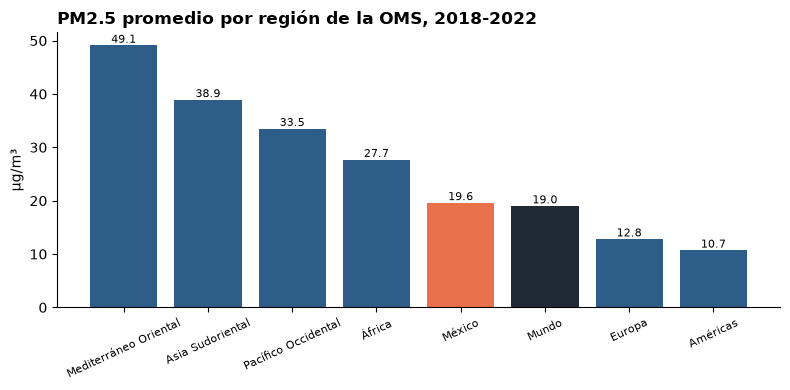

In [22]:
fig_mundo, ax = plt.subplots(figsize=(8, 4))
colores = [NARANJA if r == "México" else (TINTA if r == "Mundo" else AZUL) for r in comparacion.index]
ax.bar(comparacion.index, comparacion["PM25"], color=colores)
for x, v in enumerate(comparacion["PM25"]):
    ax.text(x, v + 0.5, f"{v:.1f}", ha="center", fontsize=8)
ax.set_title(f"PM2.5 promedio por región de la OMS, {ini}-{fin}", loc="left", fontweight="bold")
ax.set_ylabel("µg/m³")
ax.tick_params(axis="x", labelrotation=25, labelsize=8)
fig_mundo.tight_layout()
fig_mundo.savefig(OUTPUT_DIR / "pm25_contexto_mundial.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.3 Dashboard en PDF

El PDF narra todo el proceso, un estadio por sección, y cierra con el dashboard y la decisión. Se arma con `matplotlib` (`PdfPages`) para que sea reproducible desde este notebook.

In [23]:
A4 = (11.69, 8.27)

def pagina(pdf, titulo_pag, subtitulo=None):
    fig = plt.figure(figsize=A4)
    fig.text(0.05, 0.93, titulo_pag, fontsize=20, fontweight="bold", color=TINTA)
    if subtitulo:
        fig.text(0.05, 0.895, subtitulo, fontsize=10.5, color="#5A6773", style="italic")
    fig.text(0.05, 0.03, "Práctica S18 · IA Explorer TCS / TecNM (CPFIA) · Luis Saúl González Guerra",
             fontsize=8, color=GRIS)
    fig.text(0.95, 0.03, f"{pdf.get_pagecount() + 1}", fontsize=8, color=GRIS, ha="right")
    return fig

def parrafo(fig, x, y, texto, ancho=95, size=10.5, **kw):
    fig.text(x, y, textwrap.fill(texto, ancho), fontsize=size, va="top", color=kw.pop("color", TINTA),
             linespacing=1.45, **kw)

def tabla_pdf(fig, rect, df, anchos_col, size=8.5):
    ax = fig.add_axes(rect)
    ax.axis("off")
    total = sum(anchos_col)
    chars = [max(8, int(w / total * rect[2] * A4[0] * 125 / size)) for w in anchos_col]
    filas = [[textwrap.fill(str(c), n) for c, n in zip(df.columns, chars)]]
    filas += [[textwrap.fill(str(v), n) for v, n in zip(fila, chars)] for fila in df.values]
    lineas_fila = [max(t.count("\n") + 1 for t in fila) + 0.6 for fila in filas]
    t = ax.table(cellText=filas[1:], colLabels=filas[0], colWidths=[w / total for w in anchos_col],
                 bbox=[0, 0, 1, 1], cellLoc="left")
    t.auto_set_font_size(False)
    t.set_fontsize(size)
    for (r, c), celda in t.get_celld().items():
        celda.set_edgecolor("#C9D3DD")
        celda.set_height(lineas_fila[r] / sum(lineas_fila))
        celda.PAD = 0.03
        if r == 0:
            celda.set_facecolor(AZUL)
            celda.get_text().set_color("white")
            celda.get_text().set_fontweight("bold")
    return ax

def kpi_box(fig, x, y, etiqueta, valor, color=TINTA, w=0.205, h=0.13):
    ax = fig.add_axes([x, y, w, h])
    ax.set_xticks([]), ax.set_yticks([])
    ax.set_facecolor("#F4F6F8")
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(0.06, 0.78, etiqueta, fontsize=9, color="#5A6773", fontweight="bold", transform=ax.transAxes)
    ax.text(0.06, 0.18, valor, fontsize=24, color=color, fontweight="bold", transform=ax.transAxes)

with PdfPages(PDF_OUT) as pdf:
    # Portada y Excel Mindset
    fig = pagina(pdf, "Calidad del aire en México: de datos crudos a decisiones",
                 "Dashboard y proceso de análisis con Excel · Sesión 18, Excel para análisis de datos I")
    parrafo(fig, 0.05, 0.84,
            "Este reporte sigue el proceso de la Sesión 18 para responder una pregunta sobre contaminación del aire "
            "con datos públicos reales: la Base de Datos de Calidad del Aire Ambiental de la Organización Mundial de "
            "la Salud (versión 8.0, junio 2026), cuyas mediciones para México provienen del SINAICA del INECC. "
            "El área elegida es AIRE, con foco en partículas finas PM2.5, el contaminante con mayor impacto en la salud.",
            ancho=132)
    kpi_box(fig, 0.05, 0.56, f"PM2.5 promedio {ini}-{fin}", f"{kpi['pm25_nacional']:.1f} µg/m³")
    kpi_box(fig, 0.285, 0.56, "Veces sobre la guía OMS (5)", f"{kpi['veces_guia']:.1f}x", color=NARANJA)
    kpi_box(fig, 0.52, 0.56, "Mediciones sobre la guía", f"{kpi['pct_sobre_guia_pm25']:.1f}%", color=NARANJA)
    kpi_box(fig, 0.755, 0.56, "Municipios monitoreados", f"{kpi['municipios']}")
    fig.text(0.05, 0.49, "El Excel Mindset: la herramienta es el vehículo, la pregunta es el destino",
             fontsize=13, fontweight="bold", color=TINTA)
    mind = pd.DataFrame([mindset], columns=["Pregunta", "Métrica", "Dimensión", "Filtro", "Análisis accionable"])
    tabla_pdf(fig, [0.05, 0.3, 0.9, 0.15], mind, [0.24, 0.17, 0.17, 0.13, 0.24], size=9.5)
    parrafo(fig, 0.05, 0.22,
            "Entregables: libro de Excel S18_Calidad_Aire_Mexico.xlsx (estadios 1 a 8, con filtros vivos), "
            "notebook 01_calidad_aire_excel.ipynb (procesamiento reproducible) y este PDF.", ancho=132, size=9.5,
            color="#5A6773")
    pdf.savefig(fig)
    plt.close(fig)

    # Proceso completo
    fig = pagina(pdf, "El proceso: de la entrada a la decisión", "Los 8 estadios de la clase aplicados a esta práctica")
    textos = [
        ("1. Datos crudos", f"Se descargó el Excel mundial de la OMS: {len(crudo):,} filas donde cada registro es un texto CSV "
         "metido en la columna A, partido en varias celdas cuando el texto es largo. No se puede analizar así."),
        ("2. Datos limpios", f"Se reconstruyeron las columnas (Texto en columnas), se filtró México ({len(mex_crudo)} registros), "
         "se separó municipio y estado, se unificaron nombres repetidos y se dejaron vacías las mediciones con menos de "
         f"{COBERTURA_MINIMA}% de cobertura del año."),
        ("3. Tabla de Excel", f"Los {len(limpio)} registros limpios se convirtieron en la Tabla tblCalidadAire, con nombres "
         "definidos (d_PM25, d_Estado, d_Anio...) para que todas las fórmulas lean de una sola fuente."),
        ("4. Fórmulas", "SUM, AVERAGE, COUNT, COUNTA e IF responden preguntas concretas. Dos columnas calculadas: "
         "Veces_Guia_PM25 y Categoria_PM25 (IF anidado con los objetivos intermedios de la OMS)."),
        ("5. Tabla dinámica", "Promedio del contaminante con Estado en filas y Año en columnas, y un filtro para "
         "cambiar entre PM2.5, PM10 y NO2. Escala de color para ver dónde se concentra el problema."),
        ("6. Gráficos", "Barras para comparar entidades (comparación) y líneas para la evolución anual (tendencia), "
         "siempre construidas a partir de una tabla, como pide la Regla de Oro."),
        ("7. Dashboard", "Cinco KPIs y dos gráficas que responden a dos filtros (contaminante y año), con poco ruido visual."),
        ("8. Decisión", "El insight se traduce en una acción concreta: dónde invertir primero y dónde falta medir."),
    ]
    for i, (et, tx) in enumerate(textos):
        col, fila = i % 2, i // 2
        x, y = 0.05 + col * 0.46, 0.84 - fila * 0.195
        fig.text(x, y, et, fontsize=12, fontweight="bold", color=NARANJA if i == 7 else AZUL)
        parrafo(fig, x, y - 0.03, tx, ancho=72, size=9.5)
    pdf.savefig(fig)
    plt.close(fig)

    # Estadios 1-3
    fig = pagina(pdf, "Estadios 1 a 3: datos crudos, limpieza y Tabla",
                 "Reglas de higiene: sin vacíos, separación estricta y estandarización")
    fig.text(0.05, 0.84, "Así llega una fila en el archivo original (columna A):", fontsize=10, fontweight="bold", color=TINTA)
    fig.text(0.05, 0.815, textwrap.fill(lineas_mex.iloc[1][:400], 175), fontsize=7, va="top", family="monospace", color="#5A6773")
    tabla_pdf(fig, [0.05, 0.07, 0.9, 0.64], bitacora_df, [0.12, 0.3, 0.09, 0.24, 0.25], size=7.8)
    pdf.savefig(fig)
    plt.close(fig)

    # Estadio 4
    fig = pagina(pdf, "Estadio 4: fórmulas base como utilidad", "Cada fórmula responde una pregunta sobre los datos limpios")
    est = limpio["Estaciones"].sum()
    resultados = [f"{est:,}", f"{limpio['PM25'].mean():.1f} µg/m³", f"{limpio['PM25'].count():,}",
                  f"{limpio['Municipio'].count():,}",
                  "Cumple" if limpio["PM25"].mean() <= GUIA_OMS["PM2.5"] else "No cumple",
                  f"{(limpio['PM25'] <= GUIA_OMS['PM2.5']).sum():,}",
                  f"{limpio.loc[(limpio['Region'] == 'Centro') & (limpio['Anio'] == fin), 'PM25'].mean():.1f} µg/m³"]
    tabla4 = pd.DataFrame({"Fórmula": [f[0] for f in formulas], "Pregunta": [f[1] for f in formulas],
                           "En Excel": [f[2] for f in formulas], "Resultado": resultados})
    tabla_pdf(fig, [0.05, 0.32, 0.9, 0.52], tabla4, [0.1, 0.38, 0.38, 0.14], size=8.5)
    dist = limpio["Categoria_PM25"].value_counts()
    parrafo(fig, 0.05, 0.25,
            "Columna calculada Categoria_PM25 (IF anidado): " +
            "; ".join(f"{k}: {v}" for k, v in dist.items()) + ".", ancho=145, size=9.5)
    pdf.savefig(fig)
    plt.close(fig)

    # Estadio 5
    fig = pagina(pdf, "Estadio 5: tabla dinámica",
                 "PM2.5 promedio (Valores) por Estado (Filas) y Año (Columnas), en µg/m³. Ordenada de mayor a menor; "
                 "celda vacía = año sin medición válida")
    ax = fig.add_axes([0.16, 0.08, 0.76, 0.78])
    matriz = pivote_pm25.drop(columns="Promedio")
    im = ax.imshow(matriz.values, cmap="Oranges", aspect="auto")
    ax.set_xticks(range(len(matriz.columns)), [str(int(c)) for c in matriz.columns], fontsize=8)
    ax.set_yticks(range(len(matriz.index)), matriz.index, fontsize=8.5)
    for (r, c), v in np.ndenumerate(matriz.values):
        if not np.isnan(v):
            ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > np.nanpercentile(matriz.values, 75) else TINTA)
    ax.spines[:].set_visible(False)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01).set_label("µg/m³", fontsize=8)
    pdf.savefig(fig)
    plt.close(fig)

    # Estadios 6-7
    fig = pagina(pdf, "Estadios 6 y 7: dashboard", f"PM2.5 · periodo {ini}-{fin} · guía OMS anual = 5 µg/m³")
    kpi_box(fig, 0.05, 0.74, "PM2.5 promedio", f"{kpi['pm25_nacional']:.1f}", w=0.165, h=0.11)
    kpi_box(fig, 0.23, 0.74, "Veces sobre la guía", f"{kpi['veces_guia']:.1f}x", color=NARANJA, w=0.165, h=0.11)
    kpi_box(fig, 0.41, 0.74, "Sobre objetivo OI-4 (10)", f"{kpi['pct_sobre_oi4']:.0f}%", w=0.165, h=0.11)
    kpi_box(fig, 0.59, 0.74, "PM10 promedio", f"{kpi['pm10_nacional']:.1f}", w=0.165, h=0.11)
    kpi_box(fig, 0.77, 0.74, "NO2 promedio", f"{kpi['no2_nacional']:.1f}", w=0.165, h=0.11)
    ax1 = fig.add_axes([0.16, 0.09, 0.3, 0.58])
    ax1.barh(datos.index, datos.values, color=[NARANJA if e in top3.index else AZUL for e in datos.index])
    ax1.axvline(GUIA_OMS["PM2.5"], color=TINTA, ls="--", lw=1)
    ax1.set_title("PM2.5 por entidad", loc="left", fontsize=10, fontweight="bold")
    ax1.tick_params(labelsize=7.5)
    ax2 = fig.add_axes([0.55, 0.42, 0.4, 0.25])
    ax2.plot(tendencia.index, tendencia["PM25"], marker="o", color=AZUL)
    ax2.axhline(GUIA_OMS["PM2.5"], color=NARANJA, ls="--", lw=1)
    ax2.set_ylim(0, tendencia["PM25"].max() * 1.2)
    ax2.set_title("Tendencia nacional de PM2.5 vs guía OMS", loc="left", fontsize=10, fontweight="bold")
    ax2.tick_params(labelsize=7.5)
    ax3 = fig.add_axes([0.55, 0.09, 0.4, 0.24])
    ax3.bar(comparacion.index, comparacion["PM25"],
            color=[NARANJA if r == "México" else (TINTA if r == "Mundo" else AZUL) for r in comparacion.index])
    ax3.set_title(f"México frente al mundo (lugar {rank_mexico} de {len(paises)} países)", loc="left",
                  fontsize=10, fontweight="bold")
    ax3.tick_params(axis="x", labelrotation=20, labelsize=7)
    ax3.tick_params(axis="y", labelsize=7.5)
    pdf.savefig(fig)
    plt.close(fig)

    # Estadio 8
    fig = pagina(pdf, "Estadio 8: la decisión", "Del dashboard al storytelling: métrica, excepción y acción")
    fig.text(0.05, 0.83, "El insight (la verdad de los datos)", fontsize=13, fontweight="bold", color=AZUL)
    parrafo(fig, 0.05, 0.79, insight, ancho=132, size=10.5)
    fig.text(0.05, 0.62, "La decisión (la acción)", fontsize=13, fontweight="bold", color=NARANJA)
    parrafo(fig, 0.05, 0.58, decision, ancho=132, size=10.5)
    fig.text(0.05, 0.44, "Municipios con mayor PM2.5 promedio en el periodo", fontsize=10.5, fontweight="bold", color=TINTA)
    tabla_pdf(fig, [0.05, 0.16, 0.45, 0.26],
              peor_muni.reset_index().rename(columns={"PM25": "PM2.5 (µg/m³)"}), [0.45, 0.33, 0.22], size=8.5)
    fig.text(0.55, 0.44, "Limitaciones y referencias", fontsize=10.5, fontweight="bold", color=TINTA)
    parrafo(fig, 0.55, 0.41,
            "Los promedios solo incluyen municipios con estaciones; no representan a todo el país. "
            "Las comparaciones mundiales dependen de cuántas ciudades mide cada región. "
            "Fuentes: WHO Ambient Air Quality Database v8.0 (2026); WHO Global Air Quality Guidelines (2021); "
            "SINAICA, INECC; material de la Sesión 18, TCS Empowers.", ancho=68, size=8.5)
    pdf.savefig(fig)
    plt.close(fig)

print(f"PDF guardado: {PDF_OUT.relative_to(BASE_DIR)}")

PDF guardado: outputs/S18_Dashboard_Calidad_Aire_Mexico.pdf


## 8. Conclusiones

- **Hallazgo principal:** el aire de las ciudades monitoreadas de México supera de forma sistemática la guía de PM2.5 de la OMS; los valores exactos, las entidades prioritarias y la decisión están en la hoja `08_Decision` y en la última página del PDF.
- **Qué aprendí:** la mayor parte del trabajo está en los estadios 1 y 2. Un dato público oficial puede llegar sin estructura (texto en una sola columna, nombres duplicados, mediciones incompletas) y la tabla dinámica solo es confiable después de aplicar las reglas de higiene.
- **Excel Mindset:** formular primero la pregunta, la métrica y la dimensión hizo directo el mapeo a Filas, Columnas, Valores y Filtros.
- **Siguiente paso:** cruzar estos datos con población o con inventarios de emisiones, y llevar el dashboard a Power BI o a una tabla dinámica nativa con segmentadores.

## 9. Referencias

- World Health Organization. *WHO Ambient Air Quality Database, version 8.0 (update June 2026)*. https://www.who.int/publications/m/item/who-ambient-air-quality-database-(update-jun-2026)
- World Health Organization (2021). *WHO global air quality guidelines: particulate matter (PM2.5 and PM10), ozone, nitrogen dioxide, sulfur dioxide and carbon monoxide*.
- INECC. Sistema Nacional de Información de la Calidad del Aire (SINAICA). https://sinaica.inecc.gob.mx/
- TCS Empowers / TecNM CPFIA. *Sesión 18: Excel para análisis de datos I*.
- Documentación de [pandas](https://pandas.pydata.org/docs/), [openpyxl](https://openpyxl.readthedocs.io/) y [matplotlib](https://matplotlib.org/stable/).